# Customer Shopping Behavior Analysis

**Question:** *Where should a retailer spend a retention and marketing budget: which customer groups differ in how much
they spend, and which differences are big enough to act on?*

**Data:** 3,900 purchases (one row per customer), 18 columns. This notebook cleans the data (Python), reproduces the
ten SQL business questions in `sql/` as a cross-check, and tests which group differences are statistically real.

Run from the `notebooks/` folder. Paths are relative.

In [1]:
# Importing Libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RAW_PATH = Path("../data/raw/customer_shopping_behavior.csv")
CLEAN_PATH = Path("../data/cleaned/customers.csv")
FIG_DIR = Path("../docs/images")
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")

## 1. Load and inspect the raw data

In [2]:
# Importing Dataset (the file starts with a byte-order mark, so read it as utf-8-sig)
df = pd.read_csv(RAW_PATH, encoding="utf-8-sig")
print("Shape:", df.shape)
df.head()

Shape: (3900, 18)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [3]:
# Structure, statistics and missing values
df.info()
print("\nMissing values per column (only non-zero shown):")
print(df.isnull().sum()[lambda s: s > 0].to_string())
print("\nCustomer ID unique:", df["Customer ID"].is_unique, "| exact duplicate rows:", int(df.duplicated().sum()))
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   str    
 3   Item Purchased          3900 non-null   str    
 4   Category                3900 non-null   str    
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   str    
 7   Size                    3900 non-null   str    
 8   Color                   3900 non-null   str    
 9   Season                  3900 non-null   str    
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   str    
 12  Shipping Type           3900 non-null   str    
 13  Discount Applied        3900 non-null   str    
 14  Promo Code Used         3900 non-null   str    
 15

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3863.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.750065,25.351538
std,1125.977353,15.207589,23.685392,0.716983,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.800000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


## 2. Clean

In [4]:
# Filling missing Review Rating values with the median rating of the same product category
# (a global median would pull categories toward each other).
n_missing = int(df["Review Rating"].isna().sum())
df["Review Rating"] = df.groupby("Category")["Review Rating"].transform(lambda x: x.fillna(x.median()))
print(f"Imputed {n_missing} missing ratings ({n_missing / len(df):.1%} of rows).")
print("Median rating used per category:", df.groupby("Category")["Review Rating"].median().to_dict())

Imputed 37 missing ratings (0.9% of rows).
Median rating used per category: {'Accessories': 3.8, 'Clothing': 3.7, 'Footwear': 3.8, 'Outerwear': 3.8}


In [5]:
# Standardizing column names to snake_case
df.columns = df.columns.str.lower().str.replace(" ", "_")
df = df.rename(columns={"purchase_amount_(usd)": "purchase_amount"})
print(list(df.columns))

['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'payment_method', 'frequency_of_purchases']


## 3. Feature engineering

In [6]:
# age_group: quartiles of age (equal-sized groups). The boundaries are printed so the labels are not a mystery.
labels = ["Young Adult", "Adult", "Middle-aged", "Senior"]
df["age_group"] = pd.qcut(df["age"], q=4, labels=labels)
print(df.groupby("age_group", observed=True)["age"].agg(["min", "max", "count"]).reindex(labels))

             min  max  count
age_group                   
Young Adult   18   31   1028
Adult         32   44    942
Middle-aged   45   57    986
Senior        58   70    944


In [7]:
# purchase_frequency_days: categorical purchase frequency -> approximate days between purchases
frequency_mapping = {
    "Fortnightly": 14, "Weekly": 7, "Monthly": 30, "Quarterly": 90,
    "Bi-Weekly": 14, "Annually": 365, "Every 3 Months": 90,
}
df["purchase_frequency_days"] = df["frequency_of_purchases"].map(frequency_mapping)
print("Unmapped frequency values:", int(df["purchase_frequency_days"].isna().sum()))
print(df["frequency_of_purchases"].value_counts().to_string())

Unmapped frequency values: 0
frequency_of_purchases
Every 3 Months    584
Annually          572
Quarterly         563
Monthly           553
Bi-Weekly         547
Fortnightly       542
Weekly            539


In [8]:
# promo_code_used vs discount_applied: dropped only if they are identical on every row (check is printed)
identical = bool((df["discount_applied"] == df["promo_code_used"]).all())
print("promo_code_used identical to discount_applied on every row:", identical)
if identical:
    df = df.drop(columns="promo_code_used")
print(list(df.columns))

promo_code_used identical to discount_applied on every row: True
['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'previous_purchases', 'payment_method', 'frequency_of_purchases', 'age_group', 'purchase_frequency_days']


In [9]:
# Save the cleaned data. data/cleaned/customers.csv is already in the repo: check that this notebook
# reproduces it exactly instead of overwriting it.
out = df.copy()
out["age_group"] = out["age_group"].astype(str)
if CLEAN_PATH.exists():
    committed = pd.read_csv(CLEAN_PATH)
    print("Reproduces the committed customers.csv exactly:", out.reset_index(drop=True).equals(committed.astype(out.dtypes.to_dict())))
else:
    out.to_csv(CLEAN_PATH, index=False)
    print("Saved", CLEAN_PATH)

Reproduces the committed customers.csv exactly: True


## 4. Overview

In [10]:
total_rev = df["purchase_amount"].sum()
print(f"Customers (rows)        : {len(df):,}")
print(f"Total revenue           : ${total_rev:,.0f}")
print(f"Average purchase        : ${df['purchase_amount'].mean():.2f}  (median ${df['purchase_amount'].median():.0f}, range ${df['purchase_amount'].min()}-${df['purchase_amount'].max()})")
print(f"Average review rating   : {df['review_rating'].mean():.2f}")
print(f"Purchases with discount : {(df['discount_applied'] == 'Yes').mean():.1%}")
print(f"Subscribers             : {(df['subscription_status'] == 'Yes').mean():.1%}")
print(f"Male / Female customers : {(df['gender'] == 'Male').mean():.1%} / {(df['gender'] == 'Female').mean():.1%}")
print("\nRevenue by category:")
print(df.groupby("category")["purchase_amount"].agg(customers="count", revenue="sum", avg="mean").round(2).sort_values("revenue", ascending=False).to_string())

Customers (rows)        : 3,900
Total revenue           : $233,081
Average purchase        : $59.76  (median $60, range $20-$100)
Average review rating   : 3.75
Purchases with discount : 43.0%
Subscribers             : 27.0%
Male / Female customers : 68.0% / 32.0%

Revenue by category:
             customers  revenue    avg
category                              
Clothing          1737   104264  60.03
Accessories       1240    74200  59.84
Footwear           599    36093  60.26
Outerwear          324    18524  57.17


## 5. Do groups really spend different amounts?

For each grouping the notebook reports the mean purchase, a 95% confidence interval, and a significance test
(Welch's t-test for two groups, one-way ANOVA for more). With 3,900 rows, a $1 gap can look meaningful on a bar
chart and still be pure noise, so the tests decide.

In [11]:
def mean_ci(s, level=0.95):
    m, se = s.mean(), stats.sem(s)
    h = se * stats.t.ppf((1 + level) / 2, len(s) - 1)
    return m, m - h, m + h

def two_group(col, a, b, label):
    x, y = df.loc[df[col] == a, "purchase_amount"], df.loc[df[col] == b, "purchase_amount"]
    r = stats.ttest_ind(x, y, equal_var=False)
    ci = r.confidence_interval(0.95)
    sp = np.sqrt(((len(x) - 1) * x.var() + (len(y) - 1) * y.var()) / (len(x) + len(y) - 2))
    print(f"{label:<28} {a}: ${x.mean():.2f} (n={len(x):,})  {b}: ${y.mean():.2f} (n={len(y):,})  "
          f"diff {x.mean()-y.mean():+.2f} 95% CI [{ci.low:+.2f}, {ci.high:+.2f}]  Cohen's d {(x.mean()-y.mean())/sp:+.3f}  p = {r.pvalue:.3f}")

two_group("gender", "Male", "Female", "Spend per purchase, gender")
two_group("subscription_status", "Yes", "No", "Spend per purchase, subs.")
groups = [g["purchase_amount"].values for _, g in df.groupby("shipping_type")]
f = stats.f_oneway(*groups)
print(f"{'Spend by shipping type':<28} ANOVA F = {f.statistic:.2f}, p = {f.pvalue:.3f}  "
      f"(group means from ${df.groupby('shipping_type')['purchase_amount'].mean().min():.2f} to ${df.groupby('shipping_type')['purchase_amount'].mean().max():.2f})")
groups = [g["purchase_amount"].values for _, g in df.groupby("age_group", observed=True)]
f = stats.f_oneway(*groups)
print(f"{'Spend by age group':<28} ANOVA F = {f.statistic:.2f}, p = {f.pvalue:.3f}")
groups = [g["purchase_amount"].values for _, g in df.groupby("category")]
f = stats.f_oneway(*groups)
print(f"{'Spend by category':<28} ANOVA F = {f.statistic:.2f}, p = {f.pvalue:.3f}")

Spend per purchase, gender   Male: $59.54 (n=2,652)  Female: $60.25 (n=1,248)  diff -0.71 95% CI [-2.30, +0.87]  Cohen's d -0.030  p = 0.378
Spend per purchase, subs.    Yes: $59.49 (n=1,053)  No: $59.87 (n=2,847)  diff -0.37 95% CI [-2.04, +1.29]  Cohen's d -0.016  p = 0.660


Spend by shipping type       ANOVA F = 1.12, p = 0.345  (group means from $58.46 to $60.73)
Spend by age group           ANOVA F = 0.67, p = 0.573


Spend by category            ANOVA F = 1.45, p = 0.225


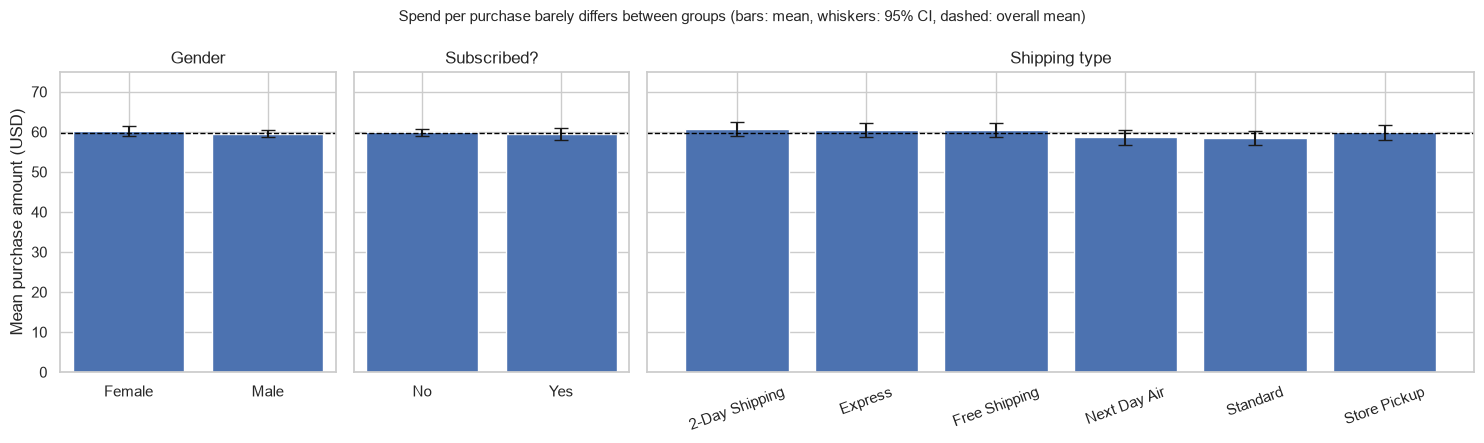

In [12]:
# Figure 1: mean purchase with 95% CI for gender, subscription and shipping type, on a shared y-axis
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True, gridspec_kw={"width_ratios": [2, 2, 6]})
for ax, col, title in zip(axes, ["gender", "subscription_status", "shipping_type"],
                          ["Gender", "Subscribed?", "Shipping type"]):
    rows = []
    for k, s in df.groupby(col)["purchase_amount"]:
        m, lo, hi = mean_ci(s)
        rows.append((k, m, m - lo))
    names, means, errs = zip(*rows)
    ax.bar(names, means, yerr=errs, capsize=5, color=sns.color_palette("deep")[0])
    ax.axhline(df["purchase_amount"].mean(), color="black", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20 if col == "shipping_type" else 0)
axes[0].set_ylabel("Mean purchase amount (USD)")
axes[0].set_ylim(0, 75)
fig.suptitle("Spend per purchase barely differs between groups (bars: mean, whiskers: 95% CI, dashed: overall mean)", fontsize=11)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_spend_by_group.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Revenue differences come from *how many* customers, not how much each spends

In [13]:
g = df.groupby("gender")["purchase_amount"].agg(customers="count", revenue="sum", avg_purchase="mean")
g["share_of_customers"] = g["customers"] / g["customers"].sum()
g["share_of_revenue"] = g["revenue"] / g["revenue"].sum()
print(g.round(3).to_string())

a = df.groupby("age_group", observed=True)["purchase_amount"].agg(customers="count", revenue="sum", avg_purchase="mean")
a["share_of_revenue"] = a["revenue"] / a["revenue"].sum()
print("\n", a.round(3).sort_values("revenue", ascending=False).to_string())

        customers  revenue  avg_purchase  share_of_customers  share_of_revenue
gender                                                                        
Female       1248    75191        60.249                0.32             0.323
Male         2652   157890        59.536                0.68             0.677

              customers  revenue  avg_purchase  share_of_revenue
age_group                                                      
Young Adult       1028    62143        60.450             0.267
Middle-aged        986    59197        60.038             0.254
Adult              942    55978        59.425             0.240
Senior             944    55763        59.071             0.239


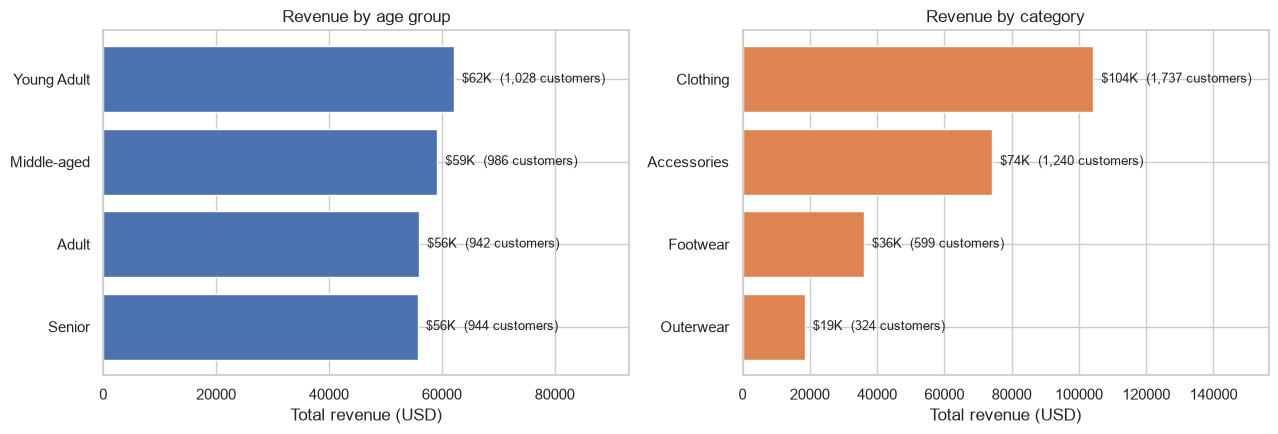

In [14]:
# Figure 2: revenue by age group and by category, labelled with customer counts
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
a = a.sort_values("revenue", ascending=False)
axes[0].barh(a.index.astype(str), a["revenue"], color=sns.color_palette("deep")[0])
for i, (r, n) in enumerate(zip(a["revenue"], a["customers"])):
    axes[0].text(r, i, f"  ${r/1000:.0f}K  ({n:,} customers)", va="center", fontsize=9)
axes[0].set_xlim(0, a["revenue"].max() * 1.5)
axes[0].invert_yaxis()
axes[0].set_title("Revenue by age group")
axes[0].set_xlabel("Total revenue (USD)")
c = df.groupby("category")["purchase_amount"].agg(customers="count", revenue="sum").sort_values("revenue", ascending=False)
axes[1].barh(c.index, c["revenue"], color=sns.color_palette("deep")[1])
for i, (r, n) in enumerate(zip(c["revenue"], c["customers"])):
    axes[1].text(r, i, f"  ${r/1000:.0f}K  ({n:,} customers)", va="center", fontsize=9)
axes[1].set_xlim(0, c["revenue"].max() * 1.5)
axes[1].invert_yaxis()
axes[1].set_title("Revenue by category")
axes[1].set_xlabel("Total revenue (USD)")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_revenue_age_category.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Discounts

The original SQL question 6 asked for the products with the **highest** share of discounted purchases but sorted
ascending, so it returned the lowest. The correct ranking is below.

In [15]:
overall_disc = (df["discount_applied"] == "Yes").mean()
disc = (df.groupby("item_purchased")["discount_applied"].apply(lambda s: (s == "Yes").mean())
          .sort_values(ascending=False))
print(f"Overall share of discounted purchases: {overall_disc:.1%}\n")
print("Top 5 products by discounted share:\n", (disc.head(5) * 100).round(1).to_string())
print("\nBottom 5 (what the original query returned):\n", (disc.tail(5) * 100).round(1).to_string())

# chi-square: does the discount share differ between products at all?
ct = pd.crosstab(df["item_purchased"], df["discount_applied"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"\nDiscount share differs across the {len(ct)} products? chi-square p = {p:.4f}")

avg = df["purchase_amount"].mean()
users = df[df["discount_applied"] == "Yes"]
hi = users[users["purchase_amount"] > avg]
print(f"\nDiscount users spending above the ${avg:.2f} average: {len(hi):,} of {len(users):,} ({len(hi)/len(users):.1%}) "
      f"| non-discount buyers above average: {(df[df['discount_applied']=='No']['purchase_amount'] > avg).mean():.1%}")
t = stats.ttest_ind(users["purchase_amount"], df[df["discount_applied"] == "No"]["purchase_amount"], equal_var=False)
print(f"Average spend with discount ${users['purchase_amount'].mean():.2f} vs without ${df[df['discount_applied']=='No']['purchase_amount'].mean():.2f}, Welch p = {t.pvalue:.3f}")

Overall share of discounted purchases: 43.0%

Top 5 products by discounted share:
 item_purchased
Hat         50.0
Sneakers    49.7
Coat        49.1
Sweater     48.2
Pants       47.4

Bottom 5 (what the original query returned):
 item_purchased
Handbag    39.9
Skirt      38.6
Sandals    36.9
Blouse     33.9
Socks      32.7

Discount share differs across the 25 products? chi-square p = 0.1292

Discount users spending above the $59.76 average: 839 of 1,677 (50.0%) | non-discount buyers above average: 50.6%
Average spend with discount $59.28 vs without $60.13, Welch p = 0.266


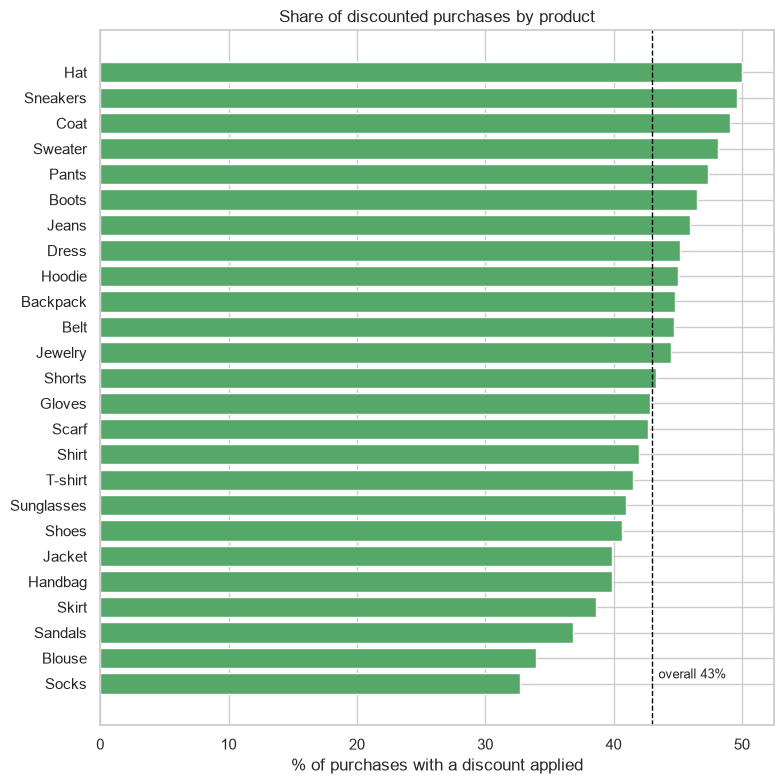

In [16]:
# Figure 3: discounted share by product
d = (disc * 100).sort_values()
plt.figure(figsize=(8, 8))
plt.barh(d.index, d.values, color=sns.color_palette("deep")[2])
plt.axvline(overall_disc * 100, color="black", linestyle="--", linewidth=1)
plt.text(overall_disc * 100 + 0.5, 0.2, f"overall {overall_disc:.0%}", fontsize=9)
plt.xlabel("% of purchases with a discount applied")
plt.title("Share of discounted purchases by product")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_discount_by_product.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Loyalty and subscription

The original segmentation (New = 1 purchase, Returning = 2 to 10, Loyal = 11+) puts about 80% of customers in
"Loyal", because `previous_purchases` runs from 1 to 50. Quartile-based cut points give groups of useful size.

In [17]:
pp = df["previous_purchases"]
print("previous_purchases: min", pp.min(), "| quartiles", pp.quantile([.25, .5, .75]).tolist(), "| max", pp.max())
old = pd.cut(pp, [-1, 1, 10, 10**6], labels=["New", "Returning", "Loyal"])
print("\nOriginal thresholds:\n", old.value_counts(normalize=True).round(3).sort_index().to_string())

df["customer_segment"] = pd.cut(pp, [-1, 13, 38, 10**6], labels=["New (1-13)", "Returning (14-38)", "Loyal (39+)"])
print("\nQuartile-based thresholds (bottom 25% / middle 50% / top 25%):")
seg = df.groupby("customer_segment", observed=True).agg(customers=("customer_id", "count"),
                                                       avg_purchase=("purchase_amount", "mean"),
                                                       subscribed=("subscription_status", lambda s: (s == "Yes").mean()))
print(seg.round(3).to_string())
f = stats.f_oneway(*[g["purchase_amount"].values for _, g in df.groupby("customer_segment", observed=True)])
print(f"Spend differs across segments? ANOVA p = {f.pvalue:.3f}")

previous_purchases: min 1 | quartiles [13.0, 25.0, 38.0] | max 50

Original thresholds:
 previous_purchases
New          0.021
Returning    0.180
Loyal        0.799

Quartile-based thresholds (bottom 25% / middle 50% / top 25%):
                   customers  avg_purchase  subscribed
customer_segment                                      
New (1-13)              1014        60.138       0.249
Returning (14-38)       1958        59.471       0.281
Loyal (39+)              928        59.975       0.270
Spend differs across segments? ANOVA p = 0.731


In [18]:
# Do repeat buyers (more than 5 previous purchases) subscribe more? Compare them with everyone ELSE, not with all customers.
df["repeat_buyer"] = pp > 5
ct = pd.crosstab(df["repeat_buyer"], df["subscription_status"])
rates = ct["Yes"] / ct.sum(axis=1)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(ct.to_string())
print(f"\nSubscription rate: repeat buyers (>5) {rates[True]:.1%} (n={ct.loc[True].sum():,}) vs others {rates[False]:.1%} (n={ct.loc[False].sum():,})")
print(f"Difference {100*(rates[True]-rates[False]):+.1f} percentage points, chi-square p = {p:.3f}")
r, pr = stats.pointbiserialr((df["subscription_status"] == "Yes").astype(int), pp)
print(f"Continuous check: correlation between previous purchases and subscribing r = {r:.3f}, p = {pr:.3f}")

# 95% CI for the difference in proportions
n1, n0 = ct.loc[True].sum(), ct.loc[False].sum()
se = np.sqrt(rates[True]*(1-rates[True])/n1 + rates[False]*(1-rates[False])/n0)
d = rates[True] - rates[False]
print(f"95% CI for the difference: [{100*(d-1.96*se):+.1f}, {100*(d+1.96*se):+.1f}] percentage points")

subscription_status    No  Yes
repeat_buyer                  
False                 329   95
True                 2518  958

Subscription rate: repeat buyers (>5) 27.6% (n=3,476) vs others 22.4% (n=424)
Difference +5.2 percentage points, chi-square p = 0.028
Continuous check: correlation between previous purchases and subscribing r = 0.031, p = 0.054
95% CI for the difference: [+0.9, +9.4] percentage points


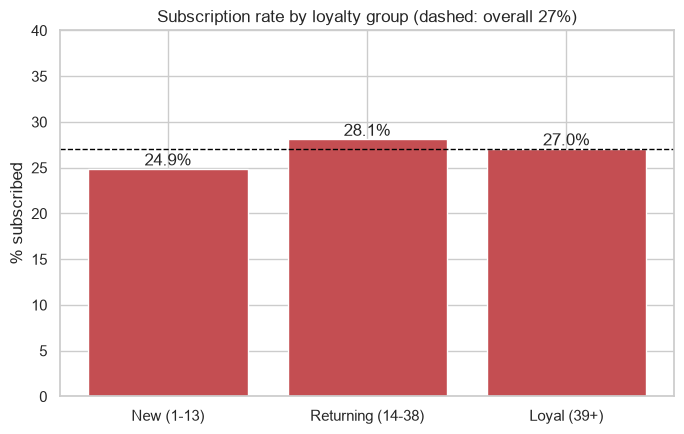

In [19]:
# Figure 4: subscription rate by loyalty group
plt.figure(figsize=(7, 4.5))
r_ = df.groupby("customer_segment", observed=True)["subscription_status"].apply(lambda s: (s == "Yes").mean() * 100)
plt.bar(r_.index, r_.values, color=sns.color_palette("deep")[3])
plt.axhline((df["subscription_status"] == "Yes").mean() * 100, color="black", linestyle="--", linewidth=1)
for i, v in enumerate(r_.values):
    plt.text(i, v + 0.4, f"{v:.1f}%", ha="center")
plt.ylabel("% subscribed")
plt.ylim(0, 40)
plt.title("Subscription rate by loyalty group (dashed: overall 27%)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_subscription_by_loyalty.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Products and ratings

In [20]:
rat = df.groupby("item_purchased")["review_rating"].agg(["mean", "count"]).sort_values("mean", ascending=False)
print("Top 5 products by average rating:\n", rat.head(5).round(2).to_string())
print(f"\nSpread: best {rat['mean'].max():.2f}, worst {rat['mean'].min():.2f}, overall {df['review_rating'].mean():.2f}")
top = (df.groupby(["category", "item_purchased"]).size().rename("orders").reset_index()
         .sort_values(["category", "orders", "item_purchased"], ascending=[True, False, True]))
top["rank"] = top.groupby("category").cumcount() + 1
print("\nTop 3 most purchased per category (ties broken alphabetically):")
print(top[top["rank"] <= 3].to_string(index=False))

Top 5 products by average rating:
                 mean  count
item_purchased             
Gloves          3.86    140
Sandals         3.84    160
Boots           3.82    144
Hat             3.80    154
Skirt           3.78    158

Spread: best 3.86, worst 3.62, overall 3.75

Top 3 most purchased per category (ties broken alphabetically):
   category item_purchased  orders  rank
Accessories        Jewelry     171     1
Accessories           Belt     161     2
Accessories     Sunglasses     161     3
   Clothing         Blouse     171     1
   Clothing          Pants     171     2
   Clothing          Shirt     169     3
   Footwear        Sandals     160     1
   Footwear          Shoes     150     2
   Footwear       Sneakers     145     3
  Outerwear         Jacket     163     1
  Outerwear           Coat     161     2


## 10. Summary

Every number below is printed by a cell above.

- **Spend per purchase is almost identical across groups.** Group means differ by at most about $3 (category: $57.17 to
  $60.26) and by under $1 for gender and subscription. None of the differences is statistically significant
  (gender p = 0.38, subscription p = 0.66, shipping p = 0.35, age group p = 0.57, category p = 0.23, loyalty group p = 0.73). See sections 5 and 8.
- **Revenue gaps are customer-count gaps.** Men are 68% of customers and 67.7% of revenue; the highest-revenue age group is
  also the largest.
- **Discounts are applied to 43% of purchases and do not go with bigger purchases**: average spend is $59.28 with a discount and
  $60.13 without (p = 0.27). The highest discount shares are Hat, Sneakers, Coat, Sweater and Pants (47-50%), but the share does
  not differ significantly across products (chi-square p = 0.13), so this is a weak signal.
- **Repeat buyers subscribe slightly more**: 27.6% vs 22.4% (+5.2 points, 95% CI +0.9 to +9.4, p = 0.03). The effect is small, rests
  on one cut-off (more than 5 purchases), and the continuous correlation is weak (r = 0.03, p = 0.054).
- **Product ratings sit in a narrow band**: 3.62 to 3.86 across all products, 3.78 to 3.86 for the top five.

**Limitations.** One dataset with unusually uniform distributions, which suggests it may be synthetic; one row per customer, so
there is no time dimension or repeat-purchase history; "revenue" is the purchase amount only (no cost or margin); statistical
significance is not business significance, and a small, real effect can still be worth acting on if the intervention is cheap.